<a href="https://colab.research.google.com/github/AadiVM2403/AML-Classwork/blob/main/AML_LAB_Midsem_Exam_Answer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Load Breast Cancer Wisconsin (Diagnostic) dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)

# Original sklearn labels: 0 = malignant, 1 = benign
# Convert to: 0 = benign, 1 = malignant
y = pd.Series(
    (data.target == 0).astype(int),
    name="diagnosis"
)

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("\nClass distribution:")
print(y.map({0: "Benign", 1: "Malignant"}).value_counts())

Dataset loaded successfully!
Dataset shape: (569, 30)

Class distribution:
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


In [2]:
# Same stratified train-test split for both classifiers
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

print("\nTesting class distribution:")
print(y_test.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

Training samples: 455
Testing samples: 114

Training class distribution:
diagnosis
Benign       285
Malignant    170
Name: count, dtype: int64

Testing class distribution:
diagnosis
Benign       72
Malignant    42
Name: count, dtype: int64


In [3]:
# Decision tree using Entropy
tree_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

tree_entropy.fit(X_train, y_train)

# Decision tree using Gini impurity
tree_gini = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

tree_gini.fit(X_train, y_train)

# Predictions
y_pred_entropy = tree_entropy.predict(X_test)
y_pred_gini = tree_gini.predict(X_test)

print("Entropy tree trained successfully!")
print("Gini tree trained successfully!")

print("\nEntropy tree accuracy:",
      accuracy_score(y_test, y_pred_entropy))

print("Gini tree accuracy:",
      accuracy_score(y_test, y_pred_gini))

Entropy tree trained successfully!
Gini tree trained successfully!

Entropy tree accuracy: 0.956140350877193
Gini tree accuracy: 0.9298245614035088


In [4]:
# Given values
benign = 12
malignant = 8
total = benign + malignant

p_benign = benign / total
p_malignant = malignant / total

# Calculate entropy
entropy = 0

for p in [p_benign, p_malignant]:
    entropy -= p * np.log2(p)

# Calculate Gini impurity
gini = 1 - (p_benign**2 + p_malignant**2)

print("Total samples:", total)
print("P(Benign):", p_benign)
print("P(Malignant):", p_malignant)
print("Entropy:", round(entropy, 4))
print("Gini Impurity:", round(gini, 4))

Total samples: 20
P(Benign): 0.6
P(Malignant): 0.4
Entropy: 0.971
Gini Impurity: 0.48


Entropy Decision Tree Evaluation
--------------------------------
Accuracy  : 0.9561
Precision : 0.9744
Recall    : 0.9048
F1-score  : 0.9383


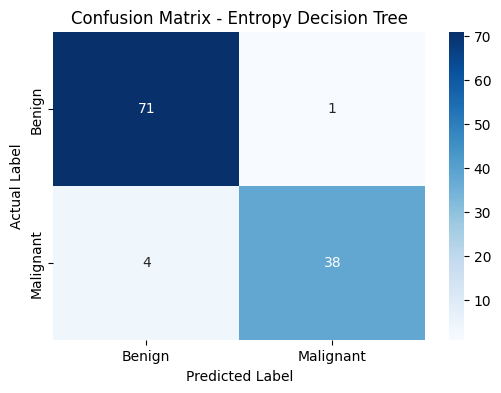


Classification Report:
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [5]:
# Select entropy classifier
y_pred = y_pred_entropy

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

print("Entropy Decision Tree Evaluation")
print("--------------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Entropy Decision Tree")
plt.show()

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

In [6]:
# Extract confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

# Malignant recall
malignant_recall = tp / (tp + fn) if (tp + fn) > 0 else 0

print("\nMalignant Recall:", round(malignant_recall, 4))
print("Malignant cases missed (False Negatives):", fn)

if fn == 0:
    print("No malignant cases were missed in this test set.")
else:
    print("Some malignant cases were missed.")
    print("Consider tuning the model to improve malignant recall.")

True Negatives (TN): 71
False Positives (FP): 1
False Negatives (FN): 4
True Positives (TP): 38

Malignant Recall: 0.9048
Malignant cases missed (False Negatives): 4
Some malignant cases were missed.
Consider tuning the model to improve malignant recall.


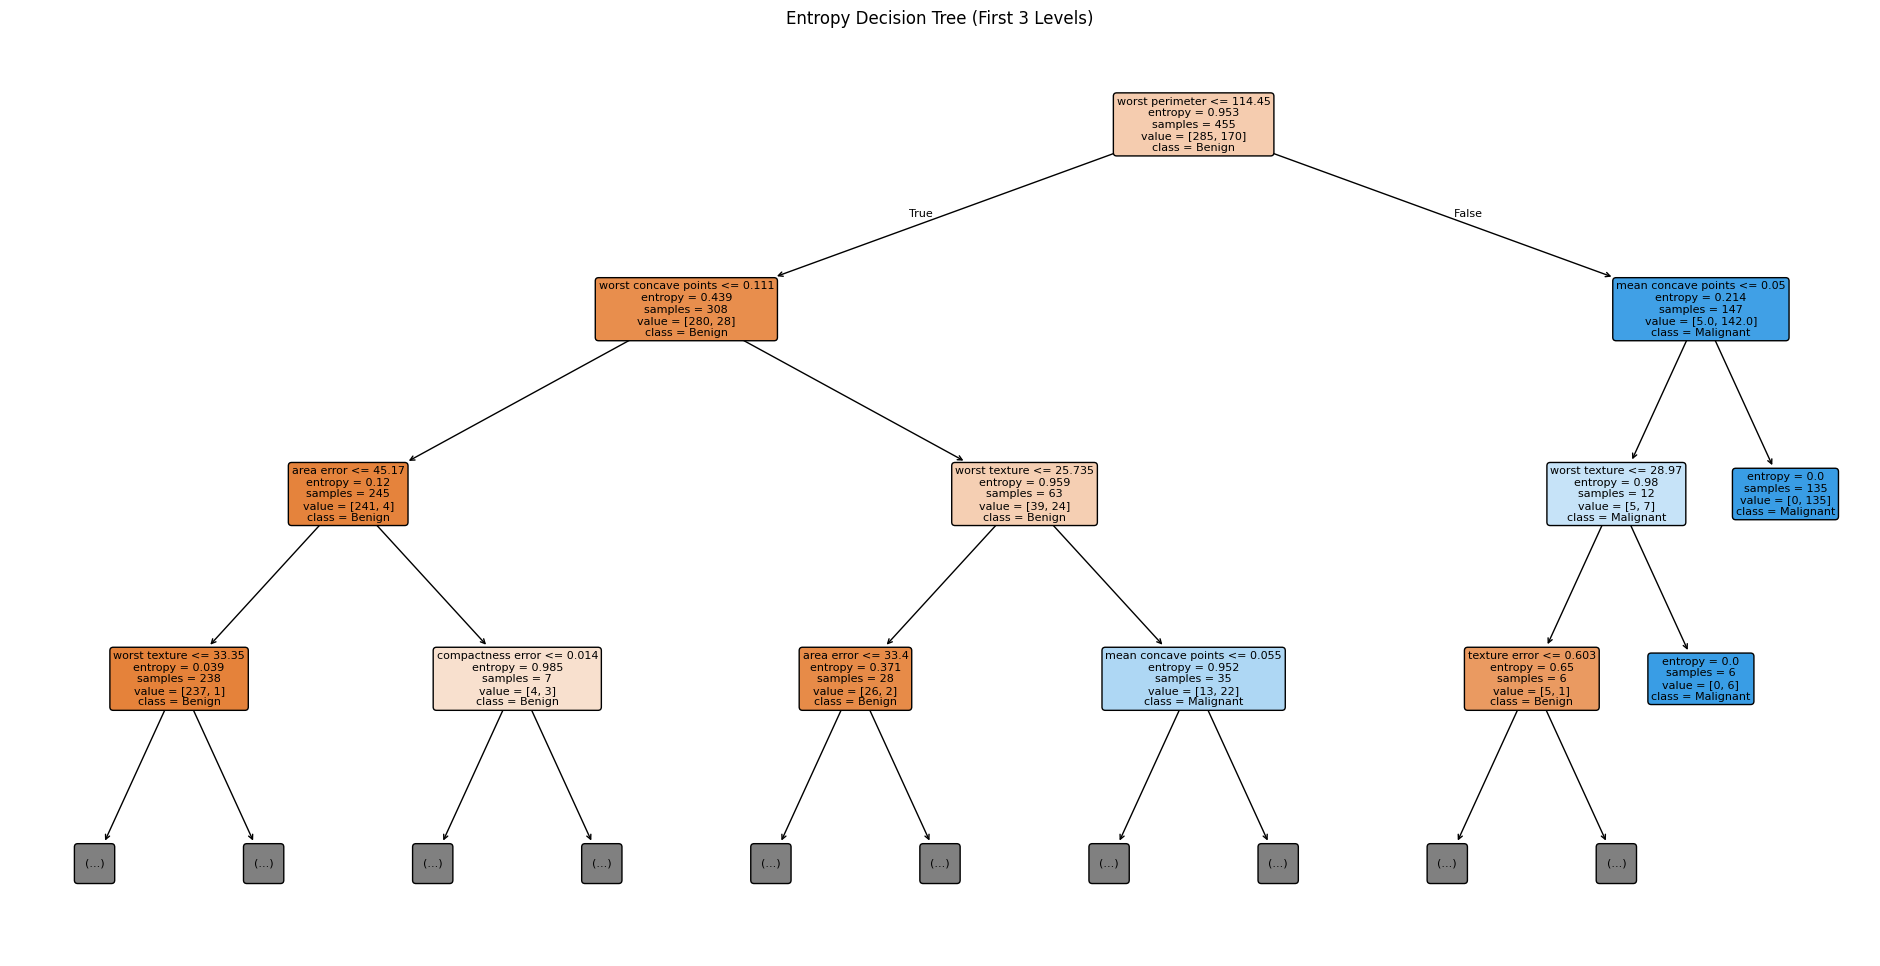

In [7]:
plt.figure(figsize=(24, 12))

plot_tree(
    tree_entropy,
    feature_names=data.feature_names,
    class_names=["Benign", "Malignant"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Entropy Decision Tree (First 3 Levels)")
plt.show()